In [9]:
!pip install -q pyspark

In [10]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

In [11]:
spark = SparkSession.builder \
    .appName("StudentPerformanceAnalysis") \
    .getOrCreate()

print("Spark Session Created Successfully!")
print("Spark Version:", spark.version)

Spark Session Created Successfully!
Spark Version: 4.0.4


In [12]:
from google.colab import files

uploaded = files.upload()

Saving dataset_synthetic.csv to dataset_synthetic (1).csv


In [5]:
file_name = next(iter(uploaded))

df = spark.read.csv(
    file_name,
    header=True,
    inferSchema=True
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.show(10, truncate=False)

+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+
|student_id|department|year|subject             |difficulty|internal_marks|attendance_pct|study_hrs_day|days_before_exam|end_sem_marks|
+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+
|1         |MECH      |3   |Maths I             |1         |43.2          |71.9          |6.9          |5               |38.7         |
|2         |IT        |2   |Maths II            |2         |43.6          |56.4          |3.9          |55              |37.2         |
|3         |CSE       |1   |Maths I             |3         |33.3          |61.4          |4.7          |49              |30.2         |
|4         |MECH      |2   |Data Structures     |3         |30.6          |98.5          |7.2          |11              |32.8         |
|5         |CIVIL     |1   |Software Engineering

In [7]:
print("Column Names:")
print(df.columns)

print("Dataset Schema:")
df.printSchema()

Column Names:
['student_id', 'department', 'year', 'subject', 'difficulty', 'internal_marks', 'attendance_pct', 'study_hrs_day', 'days_before_exam', 'end_sem_marks']
Dataset Schema:
root
 |-- student_id: integer (nullable = true)
 |-- department: string (nullable = true)
 |-- year: integer (nullable = true)
 |-- subject: string (nullable = true)
 |-- difficulty: integer (nullable = true)
 |-- internal_marks: double (nullable = true)
 |-- attendance_pct: double (nullable = true)
 |-- study_hrs_day: double (nullable = true)
 |-- days_before_exam: integer (nullable = true)
 |-- end_sem_marks: double (nullable = true)



In [8]:
print("Total Students:", df.count())
print("Total Columns:", len(df.columns))

Total Students: 300
Total Columns: 10


In [13]:
df.select([
    F.count(
        F.when(F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == ""), c)
    ).alias(c)
    for c in df.columns
]).show()

+----------+----------+----+-------+----------+--------------+--------------+-------------+----------------+-------------+
|student_id|department|year|subject|difficulty|internal_marks|attendance_pct|study_hrs_day|days_before_exam|end_sem_marks|
+----------+----------+----+-------+----------+--------------+--------------+-------------+----------------+-------------+
|         0|         0|   0|      0|         0|             0|             0|            0|               0|            0|
+----------+----------+----+-------+----------+--------------+--------------+-------------+----------------+-------------+



In [14]:
df_clean = df.dropna()

print("Rows before cleaning:", df.count())
print("Rows after cleaning:", df_clean.count())

df_clean.show(5)

Rows before cleaning: 300
Rows after cleaning: 300
+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+
|student_id|department|year|             subject|difficulty|internal_marks|attendance_pct|study_hrs_day|days_before_exam|end_sem_marks|
+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+
|         1|      MECH|   3|             Maths I|         1|          43.2|          71.9|          6.9|               5|         38.7|
|         2|        IT|   2|            Maths II|         2|          43.6|          56.4|          3.9|              55|         37.2|
|         3|       CSE|   1|             Maths I|         3|          33.3|          61.4|          4.7|              49|         30.2|
|         4|      MECH|   2|     Data Structures|         3|          30.6|          98.5|          7.2|              11|         32.

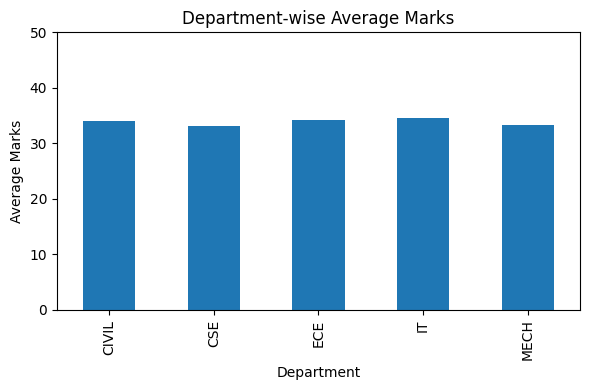

In [26]:
import matplotlib.pyplot as plt

department_avg = data.groupby("department")["end_sem_marks"].mean()

plt.figure(figsize=(6, 4))
department_avg.plot(kind="bar")
plt.title("Department-wise Average Marks")
plt.xlabel("Department")
plt.ylabel("Average Marks")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

In [27]:
plt.figure(figsize=(6, 4))

data["classification"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Student Performance Classification")
plt.ylabel("")
plt.tight_layout()
plt.show()

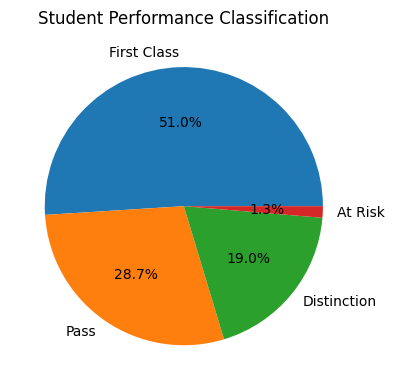

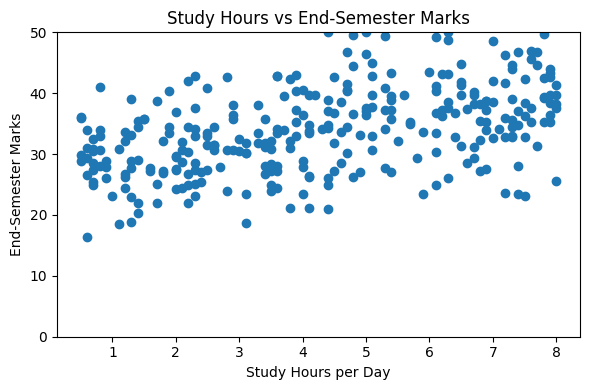

In [28]:
plt.figure(figsize=(6, 4))

plt.scatter(data["study_hrs_day"], data["end_sem_marks"])

plt.title("Study Hours vs End-Semester Marks")
plt.xlabel("Study Hours per Day")
plt.ylabel("End-Semester Marks")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

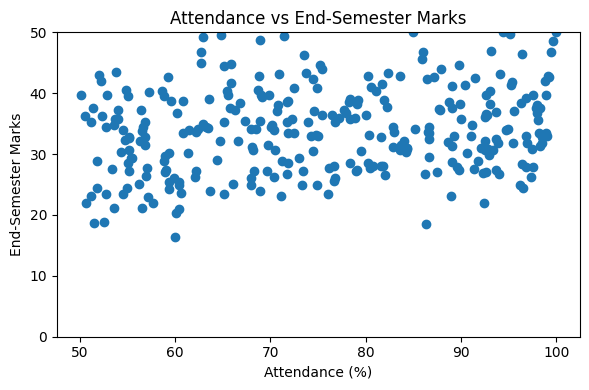

In [29]:
plt.figure(figsize=(6, 4))

plt.scatter(data["attendance_pct"], data["end_sem_marks"])

plt.title("Attendance vs End-Semester Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("End-Semester Marks")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

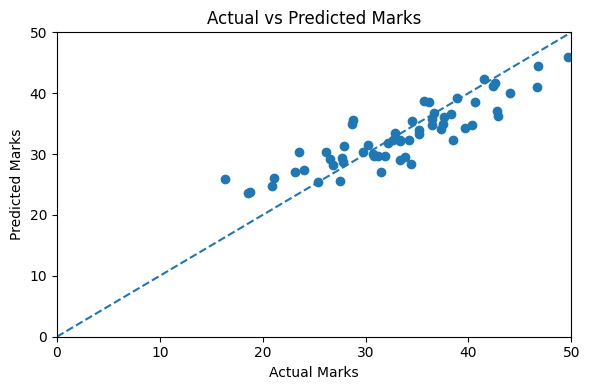

In [30]:
plt.figure(figsize=(6, 4))

plt.scatter(y_test, predictions)
plt.plot([0, 50], [0, 50], linestyle="--")

plt.title("Actual vs Predicted Marks")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.xlim(0, 50)
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

In [31]:
required_columns = [
    "student_id", "department", "year", "subject",
    "difficulty", "internal_marks", "attendance_pct",
    "study_hrs_day", "days_before_exam", "end_sem_marks"
]

numeric_columns = [
    "student_id", "year", "difficulty", "internal_marks",
    "attendance_pct", "study_hrs_day",
    "days_before_exam", "end_sem_marks"
]

df_clean = df

for col in numeric_columns:
    df_clean = df_clean.withColumn(
        col, F.col(col).cast("double")
    )

df_clean = df_clean.dropna(subset=required_columns)

df_clean = df_clean.filter(
    (F.col("end_sem_marks").between(0, 50)) &
    (F.col("internal_marks").between(0, 50)) &
    (F.col("attendance_pct").between(0, 100)) &
    (F.col("study_hrs_day") >= 0) &
    (F.col("days_before_exam") >= 0)
)

df_clean = df_clean.withColumn(
    "year", F.col("year").cast("int")
)

df_clean = df_clean.withColumn(
    "classification",
    F.when(F.col("end_sem_marks") >= 40, "Distinction")
     .when(F.col("end_sem_marks") >= 30, "First Class")
     .when(F.col("end_sem_marks") >= 20, "Pass")
     .otherwise("At Risk")
)

df_clean.cache()

print("Total records:", df_clean.count())
df_clean.show(10, truncate=False)

Total records: 300
+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+--------------+
|student_id|department|year|subject             |difficulty|internal_marks|attendance_pct|study_hrs_day|days_before_exam|end_sem_marks|classification|
+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+--------------+
|1.0       |MECH      |3   |Maths I             |1.0       |43.2          |71.9          |6.9          |5.0             |38.7         |First Class   |
|2.0       |IT        |2   |Maths II            |2.0       |43.6          |56.4          |3.9          |55.0            |37.2         |First Class   |
|3.0       |CSE       |1   |Maths I             |3.0       |33.3          |61.4          |4.7          |49.0            |30.2         |First Class   |
|4.0       |MECH      |2   |Data Structures     |3.0       |30.6          |

In [32]:
print("Overall Statistics")

df_clean.select(
    F.count("*").alias("Total_Records"),
    F.round(F.avg("end_sem_marks"), 2).alias("Average_End_Sem"),
    F.round(F.avg("internal_marks"), 2).alias("Average_Internal"),
    F.round(F.avg("attendance_pct"), 2).alias("Average_Attendance"),
    F.round(F.avg("study_hrs_day"), 2).alias("Average_Study_Hours")
).show()

print("Department-wise Performance")

df_clean.groupBy("department").agg(
    F.count("*").alias("Total_Students"),
    F.round(F.avg("end_sem_marks"), 2).alias("Average_Marks")
).orderBy(F.desc("Average_Marks")).show()

print("Classification Breakdown")

df_clean.groupBy("classification").count().show()

print("Year-wise Performance")

df_clean.groupBy("year").agg(
    F.round(F.avg("end_sem_marks"), 2).alias("Average_Marks")
).orderBy("year").show()

print("Subject-wise Performance")

df_clean.groupBy("subject").agg(
    F.round(F.avg("end_sem_marks"), 2).alias("Average_Marks")
).orderBy(F.desc("Average_Marks")).show()

Overall Statistics
+-------------+---------------+----------------+------------------+-------------------+
|Total_Records|Average_End_Sem|Average_Internal|Average_Attendance|Average_Study_Hours|
+-------------+---------------+----------------+------------------+-------------------+
|          300|          33.89|           35.71|             75.39|               4.29|
+-------------+---------------+----------------+------------------+-------------------+

Department-wise Performance
+----------+--------------+-------------+
|department|Total_Students|Average_Marks|
+----------+--------------+-------------+
|        IT|            63|        34.53|
|       ECE|            62|        34.22|
|     CIVIL|            76|        34.02|
|      MECH|            48|         33.3|
|       CSE|            51|        33.07|
+----------+--------------+-------------+

Classification Breakdown
+--------------+-----+
|classification|count|
+--------------+-----+
|   First Class|  153|
|       At Risk|

In [33]:
import pandas as pd
import gradio as gr
import plotly.express as px

data = df_clean.toPandas()

data["department"] = data["department"].astype(str)
data["subject"] = data["subject"].astype(str)
data["year"] = data["year"].astype(int)
data["classification"] = data["classification"].astype(str)

print("Dashboard data ready:", len(data), "records")
display(data.head())

Dashboard data ready: 300 records


,student_id,department,year,subject,difficulty,internal_marks,attendance_pct,study_hrs_day,days_before_exam,end_sem_marks,classification
0,1.0,MECH,3,Maths I,1.0,43.2,71.9,6.9,5.0,38.7,First Class
1,2.0,IT,2,Maths II,2.0,43.6,56.4,3.9,55.0,37.2,First Class
2,3.0,CSE,1,Maths I,3.0,33.3,61.4,4.7,49.0,30.2,First Class
3,4.0,MECH,2,Data Structures,3.0,30.6,98.5,7.2,11.0,32.8,First Class
4,5.0,CIVIL,1,Software Engineering,2.0,24.6,84.2,6.1,19.0,30.3,First Class


In [34]:
def dashboard(department, year):
    filtered = data.copy()

    if department != "All":
        filtered = filtered[
            filtered["department"] == department
        ]

    if year != "All":
        filtered = filtered[
            filtered["year"] == int(year)
        ]

    total = len(filtered)
    average = filtered["end_sem_marks"].mean() if total else 0
    at_risk = (filtered["classification"] == "At Risk").sum()
    distinction = (filtered["classification"] == "Distinction").sum()

    metrics_html = f"""
    <div style="display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:14px;width:100%;margin:10px 0 24px;">
      <div style="background:#EEF2FF;border-left:5px solid #6366F1;padding:22px 12px;border-radius:12px;text-align:center;">
        <div style="color:#4338CA;">Total Students</div>
        <div style="font-size:32px;font-weight:bold;color:#312E81;">{total}</div>
        <div style="font-size:12px;color:#4338CA;">Records analyzed</div>
      </div>
      <div style="background:#ECFDF5;border-left:5px solid #10B981;padding:22px 12px;border-radius:12px;text-align:center;">
        <div style="color:#047857;">Average End-Sem Marks</div>
        <div style="font-size:32px;font-weight:bold;color:#065F46;">{average:.2f}</div>
        <div style="font-size:12px;color:#047857;">Out of 50</div>
      </div>
      <div style="background:#FEF2F2;border-left:5px solid #EF4444;padding:22px 12px;border-radius:12px;text-align:center;">
        <div style="color:#B91C1C;">At-Risk Students</div>
        <div style="font-size:32px;font-weight:bold;color:#991B1B;">{at_risk}</div>
        <div style="font-size:12px;color:#B91C1C;">Marks below 20</div>
      </div>
      <div style="background:#FFFBEB;border-left:5px solid #F59E0B;padding:22px 12px;border-radius:12px;text-align:center;">
        <div style="color:#B45309;">Distinction</div>
        <div style="font-size:32px;font-weight:bold;color:#92400E;">{distinction}</div>
        <div style="font-size:12px;color:#B45309;">Marks 40 and above</div>
      </div>
    </div>
    """

    # Department-wise average marks
    department_data = (
        filtered.groupby("department", as_index=False)
        .agg(avg_marks=("end_sem_marks", "mean"))
    )

    bar = px.bar(
        department_data,
        x="department",
        y="avg_marks",
        title="Average End-Sem Marks by Department",
        labels={
            "department": "Department",
            "avg_marks": "Average Marks (out of 50)"
        },
        range_y=[0, 50],
        text_auto=".2f"
    )

    bar.update_layout(
        template="plotly_white",
        height=400
    )

    # Classification pie chart
    order = ["Distinction", "First Class", "Pass", "At Risk"]

    counts = (
        filtered["classification"].value_counts()
        .reindex(order, fill_value=0)
        .rename_axis("Classification")
        .reset_index(name="Students")
    )

    pie = px.pie(
        counts,
        names="Classification",
        values="Students",
        title="Performance Classification",
        hole=0.45
    )

    pie.update_layout(
        template="plotly_white",
        height=400
    )

    # Student records
    table = filtered[
        [
            "student_id", "department", "year", "subject",
            "difficulty", "internal_marks", "attendance_pct",
            "study_hrs_day", "days_before_exam",
            "end_sem_marks", "classification"
        ]
    ].head(50)

    return metrics_html, bar, pie, table

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

features = [
    "department", "year", "subject", "difficulty",
    "internal_marks", "attendance_pct",
    "study_hrs_day", "days_before_exam"
]

X = data[features]
y = data["end_sem_marks"]

categorical = ["department", "subject"]
numeric = [
    "year", "difficulty", "internal_marks",
    "attendance_pct", "study_hrs_day", "days_before_exam"
]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("numeric", SimpleImputer(strategy="median"), numeric)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))
print("R²:", round(r2_score(y_test, predictions), 3))

MAE: 2.91
RMSE: 3.63
R²: 0.754


In [36]:
new_student = pd.DataFrame([{
    "department": "CSE",
    "year": 3,
    "subject": "Maths I",
    "difficulty": 2,
    "internal_marks": 35.0,
    "attendance_pct": 80.0,
    "study_hrs_day": 4.0,
    "days_before_exam": 10
}])

predicted_marks = model.predict(new_student)[0]
predicted_marks = max(0, min(50, predicted_marks))

print(f"Predicted End-Sem Marks: {predicted_marks:.2f}/50")

Predicted End-Sem Marks: 30.49/50


In [37]:
# Dropdown choices
departments = sorted(data["department"].unique().tolist())
subjects = sorted(data["subject"].unique().tolist())
years = sorted(data["year"].unique().tolist())

def predict_new_student(
    department,
    year,
    subject,
    difficulty,
    internal_marks,
    attendance_pct,
    study_hrs_day,
    days_before_exam
):
    # Validate inputs
    if internal_marks < 0 or internal_marks > 50:
        return "Internal marks must be between 0 and 50."

    if attendance_pct < 0 or attendance_pct > 100:
        return "Attendance must be between 0 and 100%."

    if study_hrs_day < 0 or days_before_exam < 0:
        return "Study hours and days before exam cannot be negative."

    # Prepare input in the same format used to train the model
    new_student = pd.DataFrame([{
        "department": department,
        "year": int(year),
        "subject": subject,
        "difficulty": int(difficulty),
        "internal_marks": float(internal_marks),
        "attendance_pct": float(attendance_pct),
        "study_hrs_day": float(study_hrs_day),
        "days_before_exam": int(days_before_exam)
    }])

    # Predict marks out of 50
    predicted_marks = float(model.predict(new_student)[0])
    predicted_marks = max(0, min(50, predicted_marks))

    # Project-defined performance category
    if predicted_marks >= 40:
        category = "Distinction"
    elif predicted_marks >= 30:
        category = "First Class"
    elif predicted_marks >= 20:
        category = "Pass"
    else:
        category = "At Risk"

    return f"""
### 🎯 Prediction Result

**Predicted End-Semester Marks:** {predicted_marks:.2f} / 50

**Performance Category:** {category}

*This is an ML-based estimate, not a guaranteed exam result.*
"""


with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Student Performance Analytics"
) as app:

    gr.Markdown("""
    # 🎓 Student Performance Analytics
    ### Big Data Analysis using Apache Spark

    Analyze student performance and predict end-semester marks.
    """)

    # Filters for dashboard
    with gr.Row():
        department_filter = gr.Dropdown(
            choices=["All"] + departments,
            value="All",
            label="Filter Dashboard by Department"
        )
        year_filter = gr.Dropdown(
            choices=["All"] + years,
            value="All",
            label="Filter Dashboard by Year"
        )

    gr.Markdown("## 📊 Performance Overview")

    metrics_output = gr.HTML()

    gr.Markdown("## 📈 Performance Analysis")

    with gr.Row():
        bar_output = gr.Plot(label="Department Analysis")
        pie_output = gr.Plot(label="Classification Analysis")

    gr.Markdown("## 👨‍🎓 Student Records")

    table_output = gr.Dataframe(
        label="Student Records",
        interactive=False
    )

    # Dashboard event handlers
    dashboard_inputs = [department_filter, year_filter]
    dashboard_outputs = [
        metrics_output,
        bar_output,
        pie_output,
        table_output
    ]

    department_filter.change(
        fn=dashboard,
        inputs=dashboard_inputs,
        outputs=dashboard_outputs
    )

    year_filter.change(
        fn=dashboard,
        inputs=dashboard_inputs,
        outputs=dashboard_outputs
    )

    app.load(
        fn=dashboard,
        inputs=dashboard_inputs,
        outputs=dashboard_outputs
    )

    # NEW: Student marks prediction section
    gr.Markdown("---")
    gr.Markdown("## 🔮 Predict End-Semester Marks")
    gr.Markdown(
        "Enter a student's details to estimate their end-semester "
        "marks using the trained Random Forest model."
    )

    with gr.Row():
        pred_department = gr.Dropdown(
            choices=departments,
            value=departments[0],
            label="Department"
        )
        pred_year = gr.Dropdown(
            choices=years,
            value=years[0],
            label="Year"
        )
        pred_subject = gr.Dropdown(
            choices=subjects,
            value=subjects[0],
            label="Subject"
        )

    with gr.Row():
        pred_difficulty = gr.Slider(
            minimum=1,
            maximum=5,
            step=1,
            value=2,
            label="Subject Difficulty (1–5)"
        )
        pred_internal = gr.Slider(
            minimum=0,
            maximum=50,
            step=0.5,
            value=35,
            label="Internal Marks (out of 50)"
        )

    with gr.Row():
        pred_attendance = gr.Slider(
            minimum=0,
            maximum=100,
            step=1,
            value=80,
            label="Attendance (%)"
        )
        pred_study = gr.Slider(
            minimum=0,
            maximum=24,
            step=0.5,
            value=4,
            label="Daily Study Hours"
        )
        pred_days = gr.Number(
            value=10,
            minimum=0,
            precision=0,
            label="Days Before Exam"
        )

    predict_button = gr.Button(
        "Predict Marks",
        variant="primary"
    )

    prediction_output = gr.Markdown()

    predict_button.click(
        fn=predict_new_student,
        inputs=[
            pred_department,
            pred_year,
            pred_subject,
            pred_difficulty,
            pred_internal,
            pred_attendance,
            pred_study,
            pred_days
        ],
        outputs=prediction_output
    )

app.launch(share=True)

/tmp/ipykernel_556/2298934908.py:63: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://233b54966ba8dc6391.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
